# Boiling point of water vs. altitude: Snyder reference table

**Question this artifact addresses:** How well does a simple barometric formula predict the boiling point of water at different altitudes, compared with published measurements?

**Data and method:** The artifact collected water boiling-point records paired with site elevation and station pressure (0 to 4,000 m). Its search found no verified measured (Tier A or B) records. The only rows it delivers are four equation-derived Tier C reference values from the Snyder altitude table (212.0, 210.2, 208.4 and 206.6 °F at 0, 1,000, 2,000 and 3,000 ft), converted to °C.

**What you will see when this runs:** the notebook loads the data, rebuilds the Tier C reference rows with the original conversion code, checks them against the shipped file, prints a table and plots the four values. It computes no barometric prediction, because the dataset contains no measurements to compare one against.

## Install dependencies

The artifact's script uses only the Python standard library. The notebook adds matplotlib for the plot. On Colab both packages are pre-installed, so the install is skipped there.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# No packages beyond the standard library are needed except matplotlib for the plot.
# numpy and matplotlib are pre-installed on Colab, so install them locally only, at Colab's versions.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

## Imports

The original script's imports are `json` and `Path`. The figure-style block below sets the shared plot style for this run.

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


## Data loading helper

The notebook tries the GitHub copy of `mini_demo_data.json` first and falls back to the local file in this directory.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-afc680-barometric-formula-predicts-waters/main/round-2/dataset-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


## Config

This artifact has no tunable parameters: no iterations, epochs, samples or model sizes. The only constants are the source URL and access date recorded in the original script.

In [5]:
SNYDER_URL = "https://ucfoodsafety.ucdavis.edu/sites/g/files/dgvnsk7366/files/inline-files/234958_1.pdf"
ACCESS_DATE = "2026-11-22"

## Snyder altitude table: Tier C reference rows

The Snyder table states boiling points in °F at four elevations. The original script converts them to °C with `f_to_c` and labels each row as Tier C, which means equation-derived reference and not a measurement.

In [6]:
def log(message: str) -> None:
    print(message, flush=True)

def f_to_c(temp_f: float) -> float:
    return round((temp_f - 32.0) * 5.0 / 9.0, 2)

def reference_examples() -> list[dict]:
    """Tier C: boiling points stated in the Snyder table (equation-derived, reference only)."""
    stated_f = [(0, 212.0), (1000, 210.2), (2000, 208.4), (3000, 206.6)]
    examples = []
    for i, (elev_ft, boil_f) in enumerate(stated_f):
        examples.append(
            {
                "input": json.dumps({"elevation_ft": elev_ft, "pressure_source": "none stated"}, sort_keys=True),
                "output": str(f_to_c(boil_f)),
                "metadata_row_index": i,
                "metadata_tier": "C",
                "metadata_measured": False,
                "metadata_citation": f"Snyder, O. P. Jr., {SNYDER_URL}, accessed {ACCESS_DATE}",
                "metadata_task_type": "regression",
            }
        )
    return examples

reference_rows = reference_examples()
reference_rows

[{'input': '{"elevation_ft": 0, "pressure_source": "none stated"}',
  'output': '100.0',
  'metadata_row_index': 0,
  'metadata_tier': 'C',
  'metadata_measured': False,
  'metadata_citation': 'Snyder, O. P. Jr., https://ucfoodsafety.ucdavis.edu/sites/g/files/dgvnsk7366/files/inline-files/234958_1.pdf, accessed 2026-11-22',
  'metadata_task_type': 'regression'},
 {'input': '{"elevation_ft": 1000, "pressure_source": "none stated"}',
  'output': '99.0',
  'metadata_row_index': 1,
  'metadata_tier': 'C',
  'metadata_measured': False,
  'metadata_citation': 'Snyder, O. P. Jr., https://ucfoodsafety.ucdavis.edu/sites/g/files/dgvnsk7366/files/inline-files/234958_1.pdf, accessed 2026-11-22',
  'metadata_task_type': 'regression'},
 {'input': '{"elevation_ft": 2000, "pressure_source": "none stated"}',
  'output': '98.0',
  'metadata_row_index': 2,
  'metadata_tier': 'C',
  'metadata_measured': False,
  'metadata_citation': 'Snyder, O. P. Jr., https://ucfoodsafety.ucdavis.edu/sites/g/files/dgvnsk

## Measured records (Tier A/B)

The original script reads measured records from a file on disk. In the notebook the measured group comes from the loaded `data` object instead. In the shipped data this group is absent, so the list is empty.

In [7]:
def measured_examples() -> list[dict]:
    """Tier A/B rows from the measured-records group, one example per record."""
    # The notebook reads the measured group from the loaded `data` object, not a file on disk.
    groups = [g for g in data["datasets"] if g["dataset"] == "measured_boiling_point_records"]
    return groups[0]["examples"] if groups else []

measured = measured_examples()
log(f"Measured Tier A/B examples: {len(measured)}")

Measured Tier A/B examples: 0


## Assemble the standardized output

The original script writes `full_data_out.json` and its mini and preview variants. The notebook builds the same structure in memory and checks the rebuilt reference rows against the rows shipped in `mini_demo_data.json`. It does not write files.

In [8]:
groups = []
if measured:
    groups.append({"dataset": "measured_boiling_point_records", "examples": measured})
else:
    log("No measured Tier A/B records found; the measured group is omitted.")
groups.append({"dataset": "snyder_altitude_boiling_reference_tierC", "examples": reference_rows})

output = {
    "metadata": {
        "title": "Measured Boiling-Point Records by Altitude (standardized)",
        "measured_rows": len(measured),
        "tier_C_rows": len(groups[-1]["examples"]),
        "note": "Tier C rows are equation-derived reference values, not measurements.",
    },
    "datasets": groups,
}

# Check: the rebuilt reference rows must match the Tier C rows shipped in the data file.
shipped = [g for g in data["datasets"] if g["dataset"] == "snyder_altitude_boiling_reference_tierC"][0]["examples"]
assert [r["output"] for r in reference_rows] == [r["output"] for r in shipped[:len(reference_rows)]], "reference rows differ"
log(f"Measured rows: {output['metadata']['measured_rows']}; Tier C rows: {output['metadata']['tier_C_rows']}")

No measured Tier A/B records found; the measured group is omitted.


Measured rows: 0; Tier C rows: 4


## Results

The table prints each Tier C row with its elevation, boiling point in °C and measured flag. The plot shows the same four values in the reference colour. It is a reference curve, not measured data, so it is drawn in the baseline colour.

elevation_ft  boiling_C  tier  measured
           0     100.00     C     False
        1000      99.00     C     False
        2000      98.00     C     False
        3000      97.00     C     False


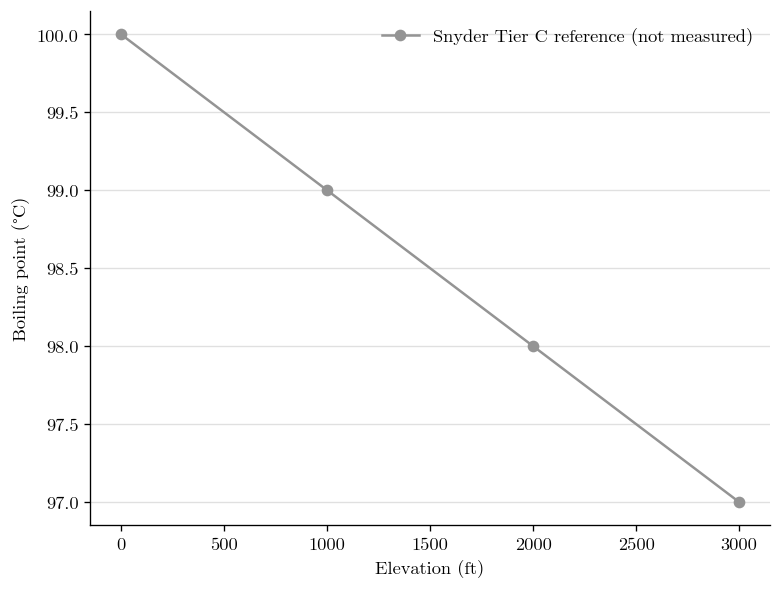

In [9]:
print(f"{'elevation_ft':>12} {'boiling_C':>10} {'tier':>5} {'measured':>9}")
for row in reference_rows:
    elev = json.loads(row["input"])["elevation_ft"]
    print(f"{elev:>12} {float(row['output']):>10.2f} {row['metadata_tier']:>5} {str(row['metadata_measured']):>9}")

elev_ft = [json.loads(r["input"])["elevation_ft"] for r in reference_rows]
boil_c = [float(r["output"]) for r in reference_rows]
fig, ax = plt.subplots()
ax.plot(elev_ft, boil_c, marker="o", color=COLOURS["baseline"], label="Snyder Tier C reference (not measured)")
ax.set_xlabel("Elevation (ft)")
ax.set_ylabel("Boiling point (°C)")
ax.legend()
plt.show()

## Interpreting the results

The four reference values fall by about 1 °C per 1,000 ft (100.0, 99.0, 98.0 and 97.0 °C at 0 to 3,000 ft). They are equation-derived from the Snyder table, not measured, and the dataset has zero measured rows.

So this run cannot test the claim the artifact is about. Whether a barometric formula predicts measured boiling points at altitude remains open. Answering it needs Tier A records (measured boiling point, site elevation and station pressure), which the search did not verify. The next steps are to transcribe the Forbes (1857) table from its page image, obtain cited elevations for each site, and match station pressure to each site and time window.